<a href="https://colab.research.google.com/github/wldnjs05/26-2-DIP-JIWONLEE/blob/main/HW05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

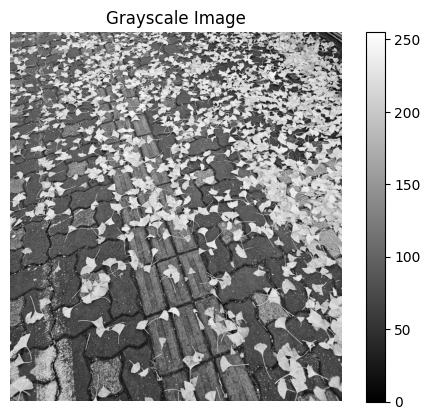

In [ ]:
I = Image.open(imgpath + '/img1.jpg').convert('L')
f = np.array(I)

plt.imshow(f, cmap='gray')
plt.axis('off')
plt.colorbar()
plt.title('Grayscale Image')
plt.show()

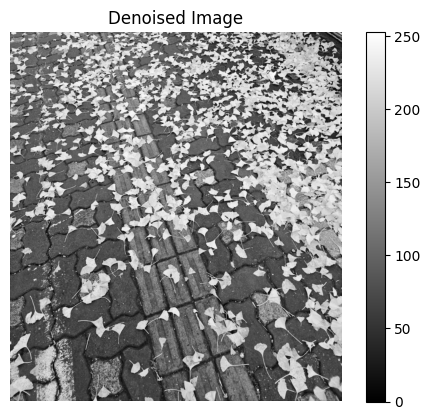

In [ ]:
f_denoised = signal.medfilt2d(f, kernel_size=7)

plt.imshow(f_denoised, cmap='gray')
plt.axis('off')
plt.colorbar()
plt.title('Denoised Image')
plt.show()

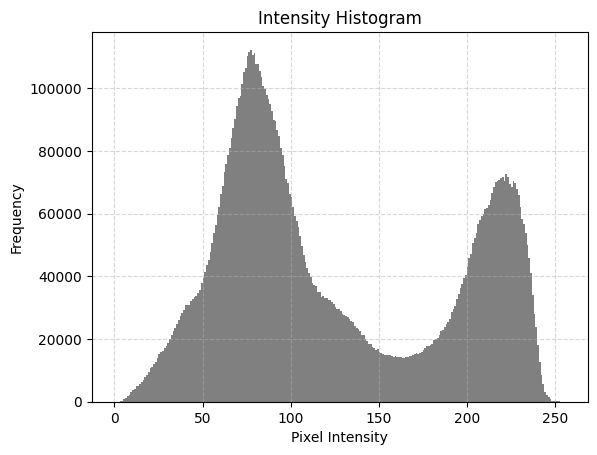

In [ ]:
plt.hist(f_denoised.ravel(), bins=256, range=(0, 256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.title('Intensity Histogram')
plt.show()

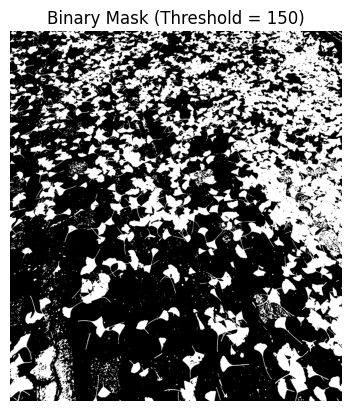

In [ ]:
th_val = 150
f_mask = f_denoised > th_val

plt.imshow(f_mask, cmap='gray')
plt.axis('off')
plt.title(f'Binary Mask (Threshold = {th_val})')
plt.show()

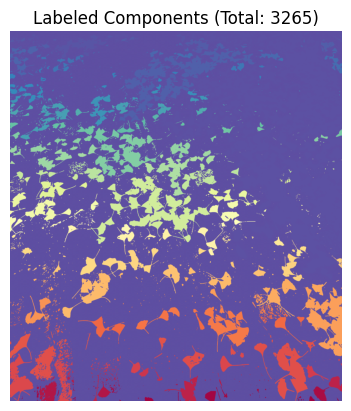

In [ ]:
labels, nums = nd.label(f_mask)

plt.imshow(labels, cmap='Spectral_r')
plt.axis('off')
plt.title(f'Labeled Components (Total: {nums})')
plt.show()

In [ ]:
cc = np.zeros((nums, 2))
for i in range(1, nums + 1):
    cc[i - 1, 0] = i
    cc[i - 1, 1] = np.sum(labels == i)
    print(f'index: {int(cc[i - 1, 0])}, number of pixels: {int(cc[i - 1, 1])}')

index: 1, number of pixels: 1112
index: 2, number of pixels: 1078
index: 3, number of pixels: 1526
index: 4, number of pixels: 10842
index: 5, number of pixels: 253
index: 6, number of pixels: 1328
index: 7, number of pixels: 597
index: 8, number of pixels: 665
index: 9, number of pixels: 1578
index: 10, number of pixels: 167184
index: 11, number of pixels: 32
index: 12, number of pixels: 1011
index: 13, number of pixels: 152
index: 14, number of pixels: 2246
index: 15, number of pixels: 33464
index: 16, number of pixels: 39
index: 17, number of pixels: 1370
index: 18, number of pixels: 794
index: 19, number of pixels: 1253024
index: 20, number of pixels: 593
index: 21, number of pixels: 36
index: 22, number of pixels: 69
index: 23, number of pixels: 320
index: 24, number of pixels: 4595
index: 25, number of pixels: 145
index: 26, number of pixels: 7
index: 27, number of pixels: 13
index: 28, number of pixels: 1
index: 29, number of pixels: 19
index: 30, number of pixels: 350
index: 31

the largest component: index 19, # of pixels: 1253024
the smallest component: index 28, # of pixels: 1


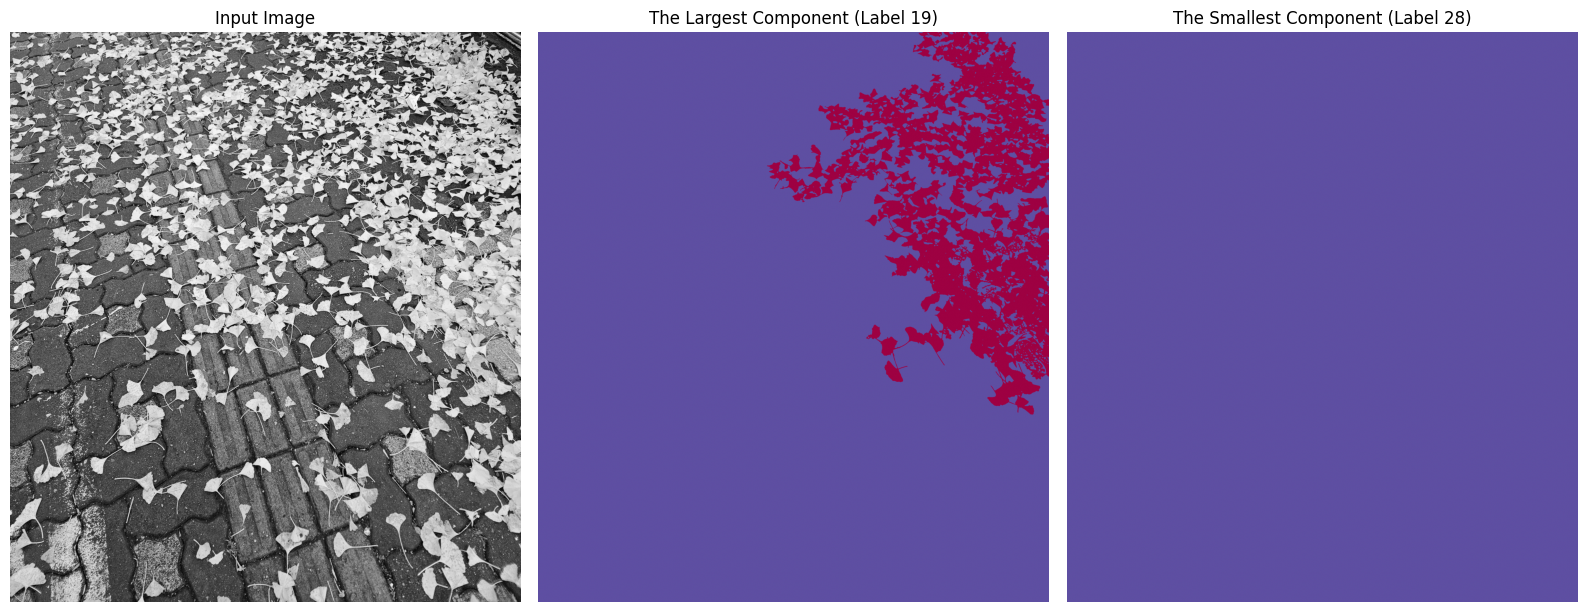

In [ ]:
ind_max = np.argmax(cc[:, 1])
max_label = int(cc[ind_max, 0])
print(f'the largest component: index {max_label}, # of pixels: {int(cc[ind_max, 1])}')

ind_min = np.argmin(cc[:, 1])
min_label = int(cc[ind_min, 0])
print(f'the smallest component: index {min_label}, # of pixels: {int(cc[ind_min, 1])}')

plt.figure(figsize=(16, 6))

plt.subplot(131)
plt.imshow(f, cmap='gray')
plt.axis('off')
plt.title('Input Image')

plt.subplot(132)
plt.imshow(labels == max_label, cmap='Spectral_r')
plt.axis('off')
plt.title(f'The Largest Component (Label {max_label})')

plt.subplot(133)
plt.imshow(labels == min_label, cmap='Spectral_r')
plt.axis('off')
plt.title(f'The Smallest Component (Label {min_label})')

plt.tight_layout()
plt.show()